# CsI–SiPM：Am241低频相关噪声的有界原生检查

2026-11-02。在英文提交`72f47d547639385f1cc48641e227643d1106e853`推送并核对远端之后继续。前一轮[互补成分方差模型](codex_0001_csi_spectral_variance_split.ipynb)明显改善了Co60，但Am241的F202仍宽约16%–18%。既有分解也显示随机分母与信号窗起伏存在耦合，本轮检验削弱平均噪声谱低频部分能否改善这一差异，同时保留PID和平均波形。

**所有比较波形均由现有C++读出程序生成。** 复用原Geant4雪崩历史、几何、光学、SiPM及平均读出参数；Python构造有限FIR参数、统计和绘图。只研究Am241，Co候选保留前一轮结果。没有新实验事件或新的独立Geant4母事件，也没有把Am主带当成纯α真值。


In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/lowfreq_taper_20261102'
def read(path):return json.loads(Path(path).read_text())
def fmt(x):return '不可估计' if x is None else f'{x:.4g}'
def ci(x):return '不可估计' if x['CI95'] is None else '['+', '.join(fmt(y) for y in x['CI95'])+f"] ({x['valid_draws']}/512)"
def table(head,rows):return '\n'.join(['|'+'|'.join(head)+'|','|'+'|'.join(['---']*len(head))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
p=read(OUT/'protocol.json');fit=read(OUT/'fit.json');a=read(OUT/'analysis.json');d=read(OUT/'decision.json')
display(Markdown('**结论：**'+d['conclusion_zh']))
for text in d['findings_zh']:display(Markdown(text))

**结论：**两折均选择identity：本轮九组低频衰减参数都未改善预定联合目标；保留上一轮配置，Am241长尺度差异仍存在。

评价折0选择identity，对折校准联合目标由0.877变为0.877。

评价折0的2MHz、目标DC幅度比0.5对照：校准F202 SD比为1.045，但QDC/平均时间/PCA SD比降至0.708/0.664/0.687。这些是原队列校准诊断，不是该对照的新完整池验证。

评价折1选择identity，对折校准联合目标由2.452变为2.452。

评价折1的2MHz、目标DC幅度比0.5对照：校准F202 SD比为1.124，但QDC/平均时间/PCA SD比降至0.752/0.653/0.735。这些是原队列校准诊断，不是该对照的新完整池验证。

r0沿用已核验完整池：F50/F102/F202 SD比0.961/1.027/1.162→0.961/1.027/1.162，F202条件95%范围[1.087,1.268]，平均ADC相对L2=0.0165。

r0联合门槛：未通过；F202_SD_ratio, F_covariance_improved。

r1沿用已核验完整池：F50/F102/F202 SD比0.965/1.069/1.176→0.965/1.069/1.176，F202条件95%范围[1.103,1.285]，平均ADC相对L2=0.0142。

r1联合门槛：未通过；F202_SD_ratio, F_covariance_improved。

## 1. 先限定候选，再原生扫描

对原有限FIR的复数频率响应$H(f)$，目标传递为

\[
H'(f)=H(f)\sqrt{\frac{f^2+(\rho f_c)^2}{f^2+f_c^2}}.
\]

固定$f_c=0.1,0.5,2.0\ \mathrm{MHz}$，$\rho=0.5,0.75,0.9$，另保留完全不变的identity配置，共10个候选。用16384点变换后截回原1025个系数。**表中的$\rho$是未截断目标的DC幅度比；实际谱须由保存的有限系数重新计算。**

设截断后未规范化的系数为$g$，配置写入$g/\|g\|$，同时把原方差强度乘以$\|g\|^2$。这样不会通过重新规范化把削弱的低频功率补回。未另拟合噪声整体幅度，未修改每个事件的ADC幅度或总功率。前一轮的差分延迟、全局/差分方差CV、静态电子噪声和平均响应全部固定。

每个评价折仅用另一实测折作为目标，原MC母事件按此前冻结的响应折分配。每个候选使用读出0/1，原队列1486个母事件共29720条逻辑读出；重复不是新的独立母事件。identity的2972条ADC必须与上一轮逐样点一致。


|评价折|候选|选中|联合目标|F50比|F102比|F202比|PID协方差误差|
|---|---|---|---|---|---|---|---|
|0|identity|True|0.877|0.9617|1.032|1.133|0.03738|
|0|f010_r050|False|1.551|0.9532|1.026|1.139|0.1635|
|0|f010_r075|False|1.097|0.9509|1.03|1.139|0.1026|
|0|f010_r090|False|1.006|0.9593|1.038|1.144|0.06819|
|0|f050_r050|False|5.632|0.9303|1.009|1.124|0.3645|
|0|f050_r075|False|2.358|0.9519|1.022|1.133|0.2252|
|0|f050_r090|False|1.175|0.9507|1.029|1.138|0.1155|
|0|f200_r050|False|10.81|0.9201|0.9799|1.045|0.4946|
|0|f200_r075|False|3.902|0.9464|1.005|1.085|0.3058|
|0|f200_r090|False|1.326|0.9482|1.023|1.119|0.1495|
|1|identity|True|2.452|0.963|1.052|1.219|0.09774|
|1|f010_r050|False|3.002|0.9483|1.039|1.202|0.1763|
|1|f010_r075|False|2.669|0.954|1.043|1.21|0.1391|
|1|f010_r090|False|2.552|0.9574|1.049|1.217|0.1144|
|1|f050_r050|False|6.368|0.9415|1.035|1.199|0.3358|
|1|f050_r075|False|3.725|0.9445|1.034|1.198|0.2258|
|1|f050_r090|False|2.751|0.9551|1.045|1.21|0.1466|
|1|f200_r050|False|10.37|0.9318|1.012|1.124|0.456|
|1|f200_r075|False|4.836|0.9417|1.02|1.151|0.2935|
|1|f200_r090|False|2.824|0.9543|1.038|1.189|0.1711|

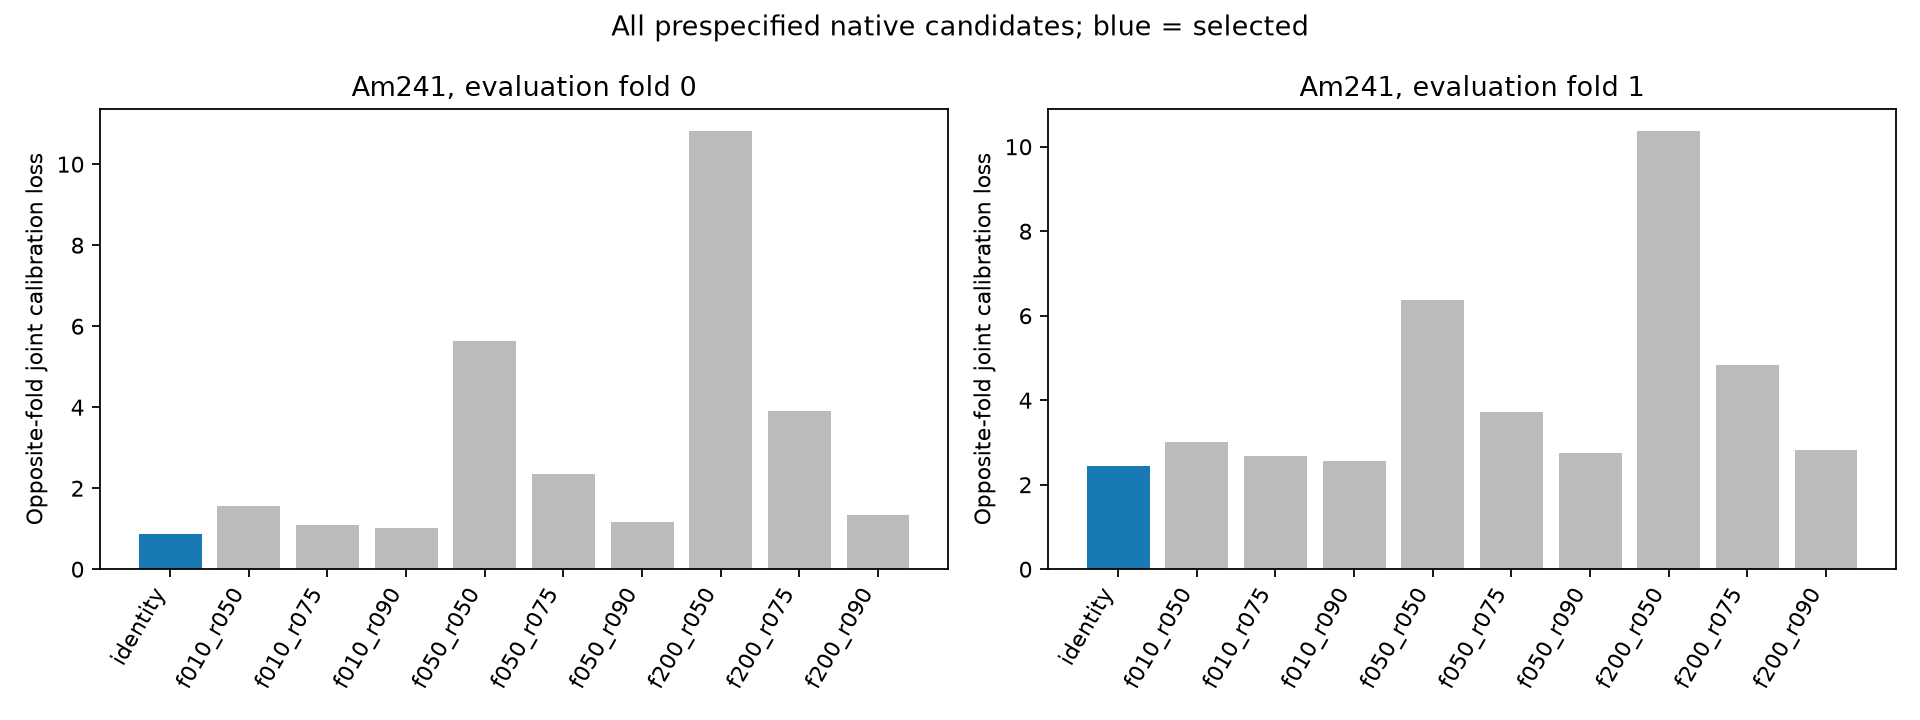

In [2]:
rows=[]
for ef,f in fit['folds'].items():
    for j,c in enumerate(f['candidates']):
        z=c['pooled_native_prediction'];rows.append([ef,c['candidate'],j==f['chosen_index'],fmt(c['loss']['total']),*[fmt(z[f'F{s}_SD_ratio']) for s in [50,102,202]],fmt(z['PID_covariance_relative_error'])])
display(Markdown(table(['评价折','候选','选中','联合目标','F50比','F102比','F202比','PID协方差误差'],rows)))
display(Image(filename=str(OUT/'figures/lowfreq_grid.png')))

## 2. 联合目标与实际有限FIR

每条读出先按自己的质量与当前Q统计，使用原支持箱和半箱质量目标；再平均两条读出的协方差、宽度平方和均值。联合目标是以下五项之和：完整F协方差六个上三角规范化残差/0.2的均方、PID协方差同类残差/0.2的均方、三个F均值相对误差/0.1的均方、PID中心50%及95%宽度相对误差/0.15的均方、平均ADC相对L2/0.03的平方。选择第一个最小值；所有候选均保留。

这一目标固定在任何新原生扫描结果出现前。没有因为完整母事件结果不理想而扩大网格或重拟合。校准只覆盖原选中队列，完整验证才能补回因新读出进入Q范围的母事件。两条校准读出不是收敛的噪声期望；后续使用同一母事件与噪声流复核属于内部研究。


|评价折|候选|校准实测数|评价实测数|实际FIR功率比|截断丢失功率比例|实际DC功率比|
|---|---|---|---|---|---|---|
|0|identity|214|193|1|0|1|
|1|identity|193|214|1|0|1|

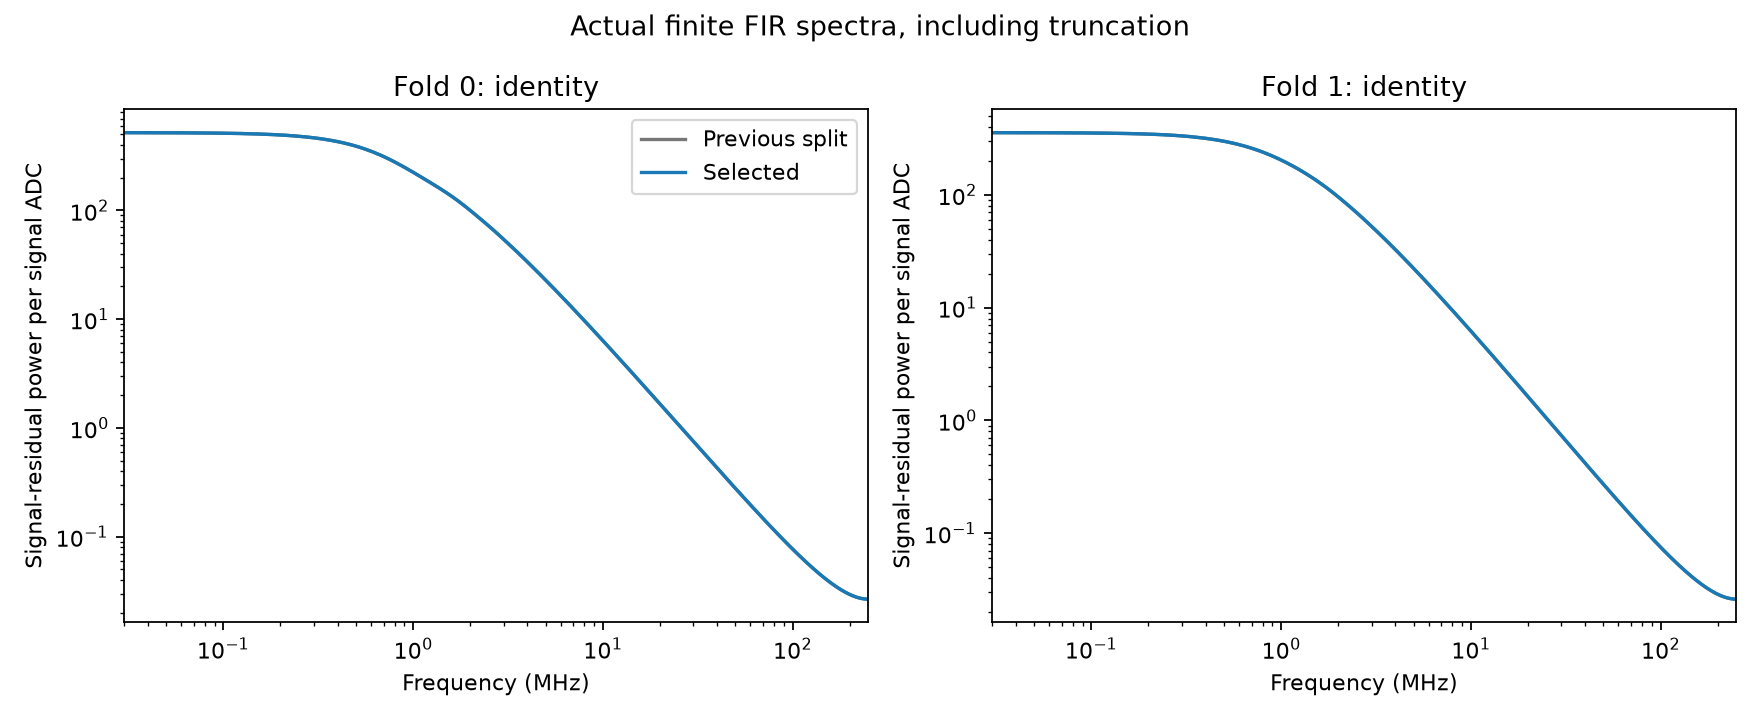

In [3]:
rows=[]
for ef,f in fit['folds'].items():
    c=p['configs'][ef][f['candidate']];m=read(PROJECT/f['config'])['signal_dependent_noise'];old=read(PROJECT/c['source_config'])['signal_dependent_noise']
    actual_dc=m['variance_per_signal_adc']*sum(m['coefficients'])**2/(old['variance_per_signal_adc']*sum(old['coefficients'])**2)
    rows.append([ef,f['candidate'],len(f['training_ids']),len(f['evaluation_ids']),fmt(c['kernel_power_ratio']),fmt(c['outside_original_FIR_power_fraction']),fmt(actual_dc)])
display(Markdown(table(['评价折','候选','校准实测数','评价实测数','实际FIR功率比','截断丢失功率比例','实际DC功率比'],rows)))
display(Image(filename=str(OUT/'figures/lowfreq_spectra.png')))

## 3. 复用完整192000个Am241母事件的已封存检查

两折均选择identity，参数与前轮split逐项完全相同，因此复用前轮192000个完整母事件的已封存原生读出，不重复生成相同波形。原验证包含384000条原参数/零CV控制ADC闭合和384000条split读出；这些是**本轮引用的既有结果，不是新增读出**。本轮新产生的原生读出只有网格扫描的29720条。`reuse_lowfreq_full.py`只在两个选定配置与既有完整池配置完全相等时允许这一分支。

完整池既有提取已使用全批次基线RMS、质量、幅度≥200、t10≥384、当前电荷及所有特征，本轮以逐字节相同的数组引用，并从原ROOT抽取全部共同范围事件重新核验。完整池质量参考不由原选中小队列估计。实验支持箱、半箱质量目标、PCA、对折定义保持冻结。

本轮identity没有新进入或离开事件。确认数组、队列、计数逐项相同后，直接沿用前轮512组实验块/母事件的配对结果，不重新抽样，也不把这些区间说成新验证。上一轮split的两条完整池点估计及全部512组结果必须逐项闭合。区间固定拟合与已实现噪声，不含重新选择候选等误差。


|模型/读出|支持母事件|比前轮移入|比前轮移出|F50比|F102比|F202比|F202条件95%范围|
|---|---|---|---|---|---|---|---|
|previous_r0|1399|0|0|0.9611|1.027|1.162|[1.087, 1.268] (512/512)|
|taper_r0|1399|0|0|0.9611|1.027|1.162|[1.087, 1.268] (512/512)|
|previous_r1|1411|0|0|0.9646|1.069|1.176|[1.103, 1.285] (512/512)|
|taper_r1|1411|0|0|0.9646|1.069|1.176|[1.103, 1.285] (512/512)|

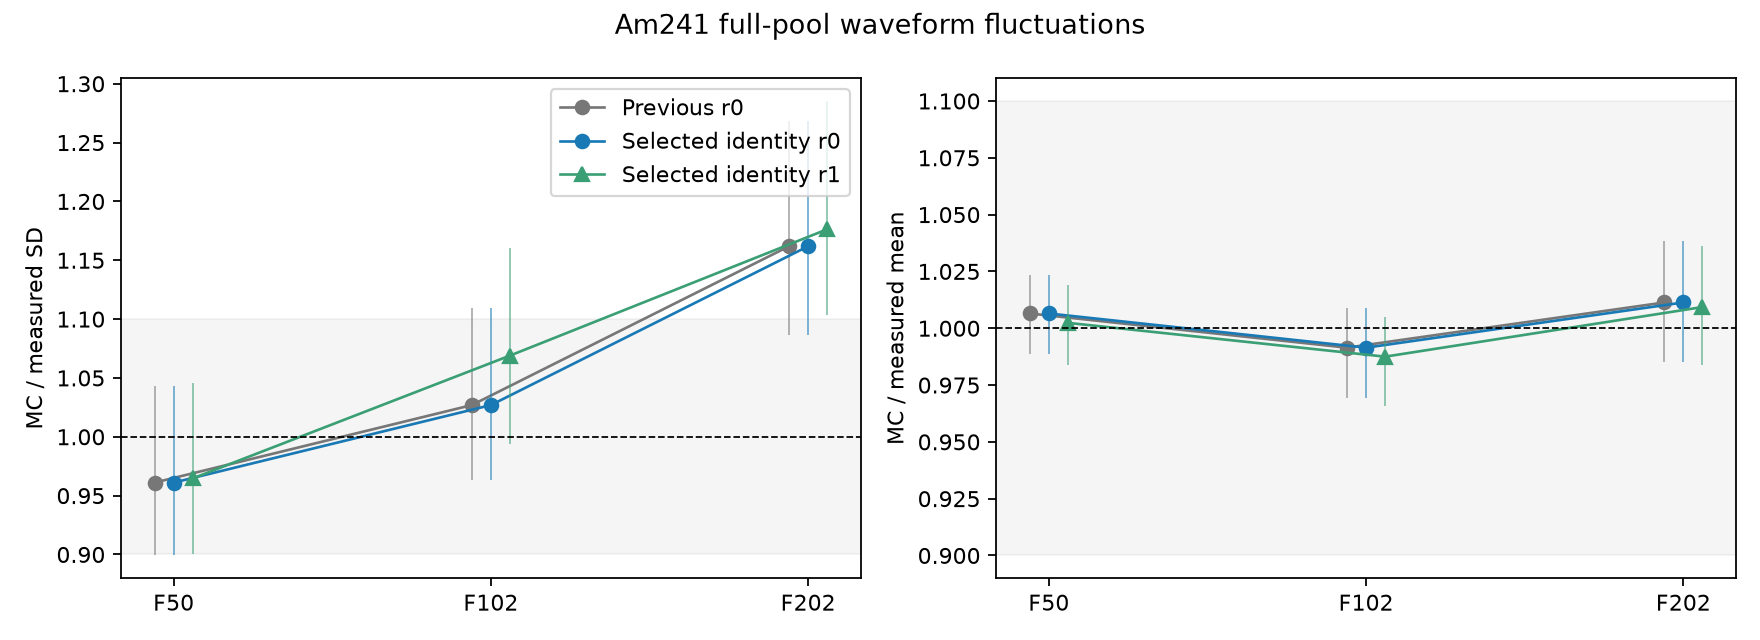

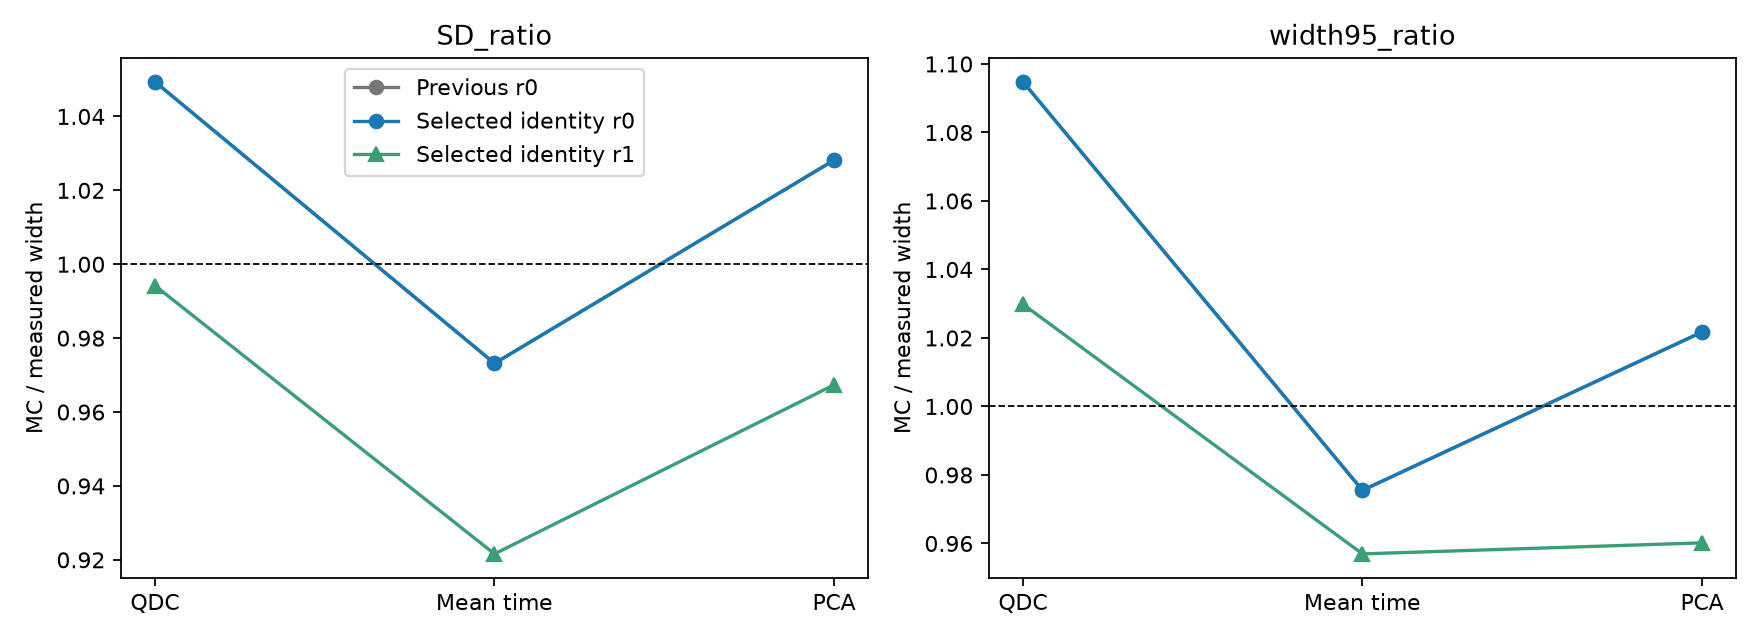

|读出|F50配对变化范围|F102配对变化范围|F202配对变化范围|
|---|---|---|---|
|0|[0, 0] (512/512)|[0, 0] (512/512)|[0, 0] (512/512)|
|1|[0, 0] (512/512)|[0, 0] (512/512)|[0, 0] (512/512)|

In [4]:
rows=[]
for v,r in a['variants'].items():
    sel=a['selection'][v];rows.append([v,sum(x['supported'] for x in sel),sum(x['enter'] for x in sel),sum(x['leave'] for x in sel),*[fmt(r['point'][f'F{s}_SD_ratio']) for s in [50,102,202]],ci(r['CI95']['F202_SD_ratio'])])
display(Markdown(table(['模型/读出','支持母事件','比前轮移入','比前轮移出','F50比','F102比','F202比','F202条件95%范围'],rows)))
display(Image(filename=str(OUT/'figures/lowfreq_scales.png')))
display(Image(filename=str(OUT/'figures/lowfreq_pid.png')))
rows=[]
for r in [0,1]:
    z=a['variants'][f'taper_r{r}']['change_vs_previous'];rows.append([r,*[ci(z['CI95'][f'F{s}_SD_ratio']) for s in [50,102,202]]])
display(Markdown(table(['读出','F50配对变化范围','F102配对变化范围','F202配对变化范围'],rows)))

## 4. 联合门槛、分折与限制

继承上轮预定门槛：三尺度F均值/SD和三个PID SD比均为0.9–1.1；PID中心50%/95%宽度比为0.85–1.15；平均ADC相对L2不得比同流前轮结果恶化超过0.002，PID规范化协方差误差不得恶化超过0.02，F协方差误差须改善。两个读出分别检查。这些是数值筛查，汇总通过不等于每折稳定，也不是等效性证明。


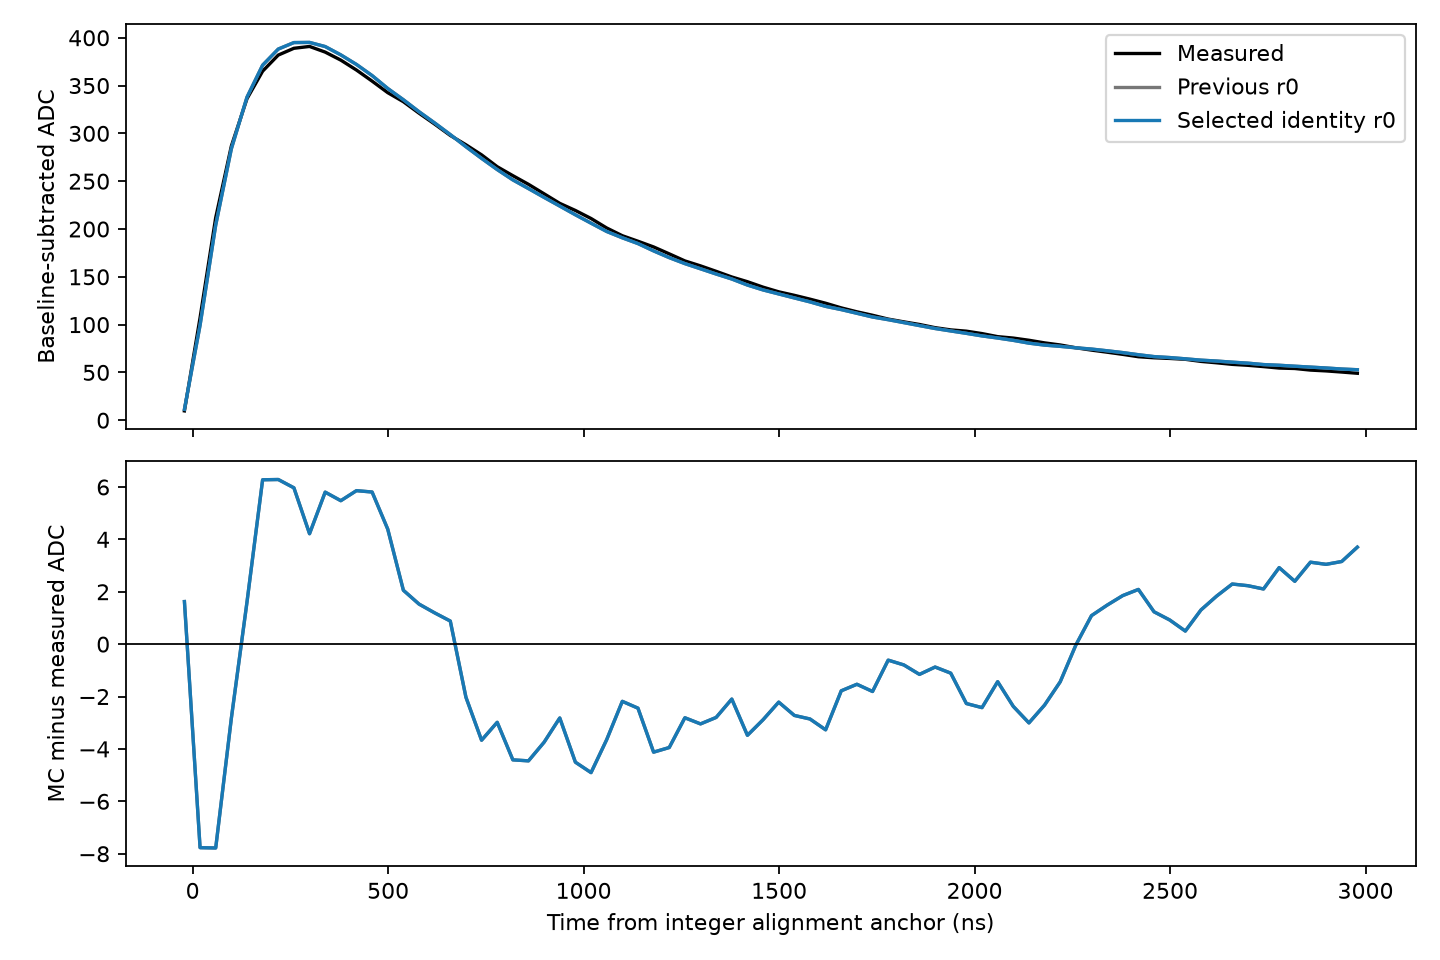

|读出|均ADC L2|PID协方差误差|F协方差误差|通过|未通过项|
|---|---|---|---|---|---|
|0|0.01654|0.05679|0.1325|False|F202_SD_ratio, F_covariance_improved|
|1|0.01422|0.09982|0.1593|False|F202_SD_ratio, F_covariance_improved|

|评价折|候选|F50比|F102比|F202比|
|---|---|---|---|---|
|0|taper_r0|0.9265|1.072|1.236|
|0|taper_r1|0.8753|1.072|1.2|
|1|taper_r0|1.006|0.9797|1.106|
|1|taper_r1|1.049|1.045|1.16|

边界：全部实验段及原MC母事件均已探索；对折隔离新增校准层，不是盲验证。

边界：参数网格比较两条已实现读出，拟合后仍用相同原母事件池复核；这不是新的噪声或输运验证。

边界：低频传递函数只是经验读出敏感性，有限FIR截断会改变实际频率响应；报告实际系数频谱，不能当成已测量的电路。

边界：条件512组区间固定拟合、参考、质量阈值及已实现噪声，不包含网格选择、拟合误差、系统误差或噪声平均。

边界：校准原队列不能补回外部母事件，最终结果必须以全部192000个母事件的当前选择为准。

边界：Am含alpha及gamma/电子；这里没有实验粒子真值，也未更新ROC或硬件触发效率。

**下一步：**依据完整网格的PID与三尺度权衡，检验有限时间相关结构及随机分母耦合；保留本轮全部失败项，不继续扩大同一低频衰减网格来追逐单个指标。

In [5]:
display(Image(filename=str(OUT/'figures/lowfreq_mean_adc.png')))
rows=[]
for r in [0,1]:
    x=a['variants'][f'taper_r{r}']['point'];g=a['joint_guards'][str(r)];rows.append([r,fmt(x['mean_ADC_relative_L2']),fmt(x['PID_covariance_relative_error']),fmt(x['F_covariance_relative_error']),g['passed'],', '.join(g['failed']) or '无'])
display(Markdown(table(['读出','均ADC L2','PID协方差误差','F协方差误差','通过','未通过项'],rows)))
rows=[]
for ef,values in a['fold_checks'].items():
    for v in ['taper_r0','taper_r1']:rows.append([ef,v,*[fmt(values[v][f'F{s}_SD_ratio']) for s in [50,102,202]]])
display(Markdown(table(['评价折','候选','F50比','F102比','F202比'],rows)))
for limit in d['limitations_zh']:display(Markdown('边界：'+limit))
display(Markdown('**下一步：**'+d['next_work_zh']))

## 5. 复现、断点恢复与封存

本轮实际流程：`prepare_lowfreq.py` → `run_lowfreq_grid.py` → `fit_lowfreq.py` → `reuse_lowfreq_full.py` → `analyze_lowfreq.py` → `report_lowfreq.py` → 本笔记生成器 → `verify_lowfreq.py`及`--archive`。若选出非identity配置，则必须走`run_lowfreq_full.py`、`extract_lowfreq.py`的新完整池重放；本轮未运行该分支。原生程序复用前轮已通过测试的构建，二进制哈希写入方案。完整重跑须使用新目录。

网格运行会话中断后，已有80份原生输出与49份特征文件。修改运行器仅允许复用经校验的完整原生批次、逐项比较已存在的有效数组，不覆盖已有完整产物。原方案、原运行器及129个文件的哈希分别保留于`pre_resume_protocol_v1.json`、`pre_resume_run_lowfreq_grid_v1.py`及`resume_record.json`。发现一份NPZ未写完，原字节保留在`interrupted_artifacts/`，仅从完整ROOT重新提取该文件；映射见`interrupted_output_recovery.json`。模型、网格、目标、母事件和随机种子没有改变。

最终核验包括配置只改变规定FIR参数、所有原生/数值文件来源、identity ADC复现、有界网格联合目标重算、完整母事件覆盖、候选共同范围事件的原ADC特征重算、随机/边界质量检查、配对512组闭合、直接加权二阶矩及已执行笔记。`record.json`保存输出哈希及源码快照。默认配置、正式PID和共享文献库保持原样。本轮新研究改动尚未提交；前一轮提交与push已完成。
